In [ ]:
# 3. Implement the "Five Cs of Data Visualization"(Clean, Clear, Concise, Captivating, Contextual) using
# a sample dataset.
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("./stddata.csv")
print(df.head())

  Student_ID Student_Name  Python_Marks  Statistics_Marks  Data_Science_Marks  \
0       S001         Asha            85                78                  90   
1       S002         Ravi            70                65                  72   
2       S003        Priya            92                88                  95   
3       S004        Kiran            60                55                  62   
4       S005        Meena            80                82                  85   

   Attendance_Percent  Average_Marks Result  
0                  96          84.33   Pass  
1                  82          69.00   Pass  
2                  98          91.67   Pass  
3                  75          59.00   Pass  
4                  90          82.33   Pass  


In [2]:
#subject columns
subjects = ["Python_Marks","Statistics_Marks","Data_Science_Marks"]
#1. Clean: Remove duplicates and handle missing values

df=df.drop_duplicates()
df=df.dropna(
    subset=["Student_Name"]+subjects+["Attendance_Percent"]
)
# calculate average marks

df["Average_Marks"]=df[subjects].mean(axis=1)

# calculate pass/fail result (min 40 in subject)

df["Result"] = df[subjects].ge(40).all(axis=1).map({True: "pass",False: "Fail"})

print("\nCleaned Dataset")
print(df.head())


Cleaned Dataset
  Student_ID Student_Name  Python_Marks  Statistics_Marks  Data_Science_Marks  \
0       S001         Asha            85                78                  90   
1       S002         Ravi            70                65                  72   
2       S003        Priya            92                88                  95   
3       S004        Kiran            60                55                  62   
4       S005        Meena            80                82                  85   

   Attendance_Percent  Average_Marks Result  
0                  96      84.333333   pass  
1                  82      69.000000   pass  
2                  98      91.666667   pass  
3                  75      59.000000   pass  
4                  90      82.333333   pass  


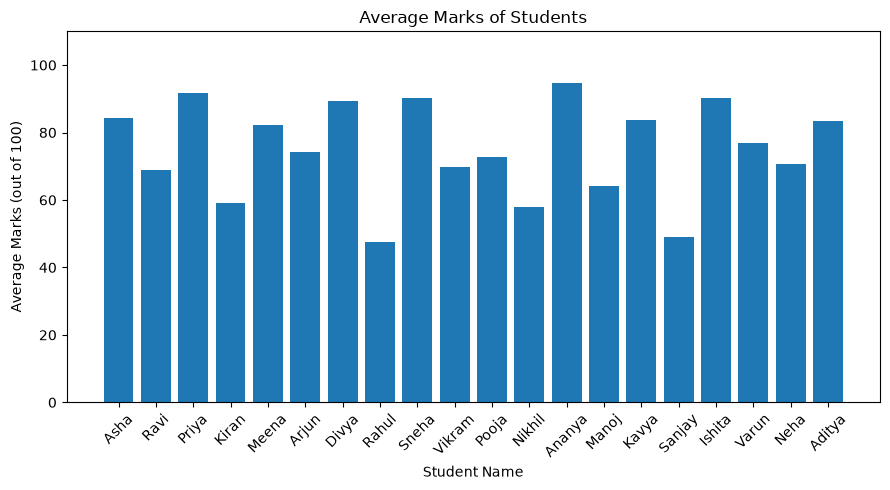

In [3]:
# 2. CLEAR: Display average marks with a meaningful title
plt.figure(figsize=(9,5))
plt.bar(df["Student_Name"], df["Average_Marks"])
plt.title("Average Marks of Students")
plt.xlabel("Student Name")
plt.ylabel("Average Marks (out of 100)")
plt.xticks(rotation=45)
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

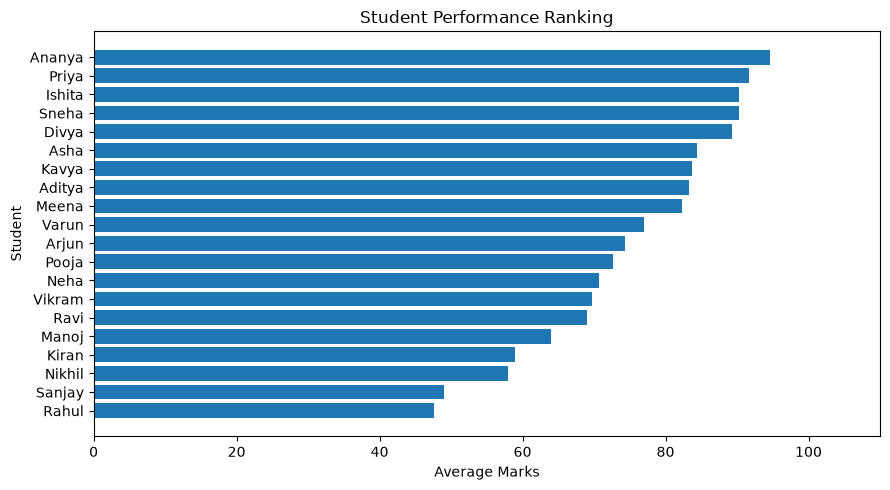

In [4]:
# 3. CONCISE: Show only relevant information
sorted_df = df.sort_values("Average_Marks")

plt.figure(figsize=(9,5))
plt.barh(
    sorted_df["Student_Name"],
    sorted_df["Average_Marks"]
)

plt.title("Student Performance Ranking")
plt.xlabel("Average Marks")
plt.ylabel("Student")
plt.xlim(0, 110)
plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

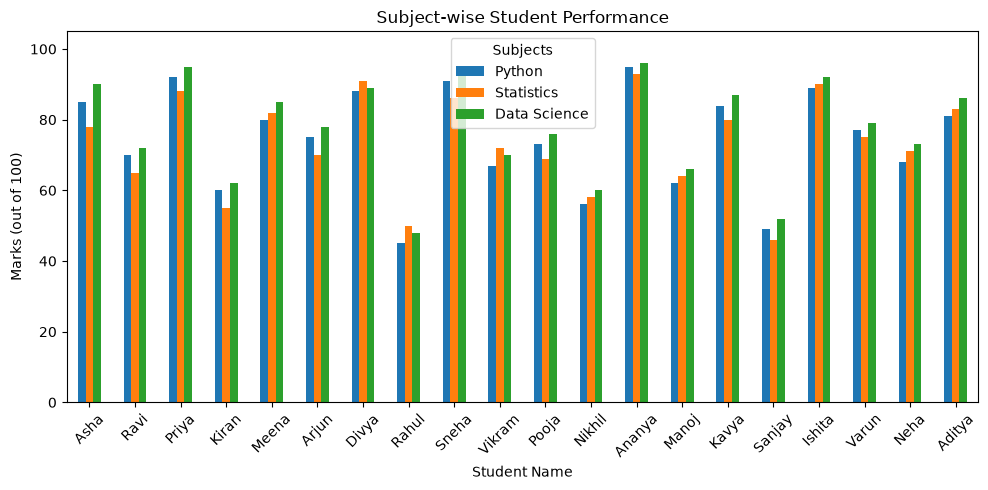

In [5]:
# 4. CAPTIVATING: Compare marks across subjects
df.plot(
    x="Student_Name",
    y=subjects,
    kind="bar",
    figsize=(10,5)
)

plt.title("Subject-wise Student Performance")
plt.xlabel("Student Name")
plt.ylabel("Marks (out of 100)")
plt.ylim(0, 105)
plt.legend(
    ["Python", "Statistics", "Data Science"],
    title="Subjects"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show

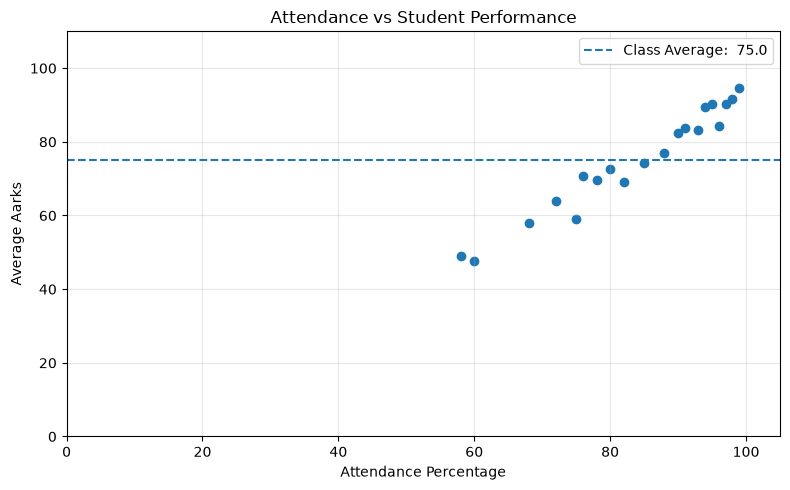

In [9]:
# 5. CONTEXTUAL: Compare attendance with averoge marks
class_average = df["Average_Marks"].mean()
plt.figure(figsize=(8,5))
plt.scatter(
    df["Attendance_Percent"],
    df["Average_Marks"]
)
plt.axhline(
    class_average,
    linestyle="--",
    label = f"Class Average: {class_average : .1f}"
)
plt.title("Attendance vs Student Performance")
plt.xlabel("Attendance Percentage")
plt.ylabel("Average Aarks")
plt.xlim(0, 105)
plt.ylim(0, 110)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()